In [4]:
from gurobipy import Model, GRB, quicksum
import pandas as pd
import numpy as np
import math
import os


# =========================
# 1. 读取 CSV
# =========================
input_file = "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE2027July/fused data.csv"

years = list(range(2010, 2025))
WINDOW_LEN = 10
CR_GROWTH = 0.01

df = pd.read_csv(input_file, encoding="utf-8-sig")

df.columns = (
    df.columns.astype(str)
    .str.replace("\n", " ", regex=False)
    .str.replace("\r", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

for year in years:
    cr_col = f"Nb CR {year}"
    if cr_col not in df.columns:
        df[cr_col] = 0.0
    df[cr_col] = pd.to_numeric(
        df[cr_col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    ).fillna(0.0)

mass_col = "Masse rejetée à chaque CR (kg)"
if mass_col not in df.columns:
    raise ValueError(f"找不到列: {mass_col}")

df[mass_col] = pd.to_numeric(
    df[mass_col].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
).fillna(0.0)

if "N Equipement" not in df.columns:
    raise ValueError("找不到列: N Equipement")

N = len(df)


# =========================
# 2. 参数
# =========================
C_MANT = 47000
C_LEAK = 2520
mu_MANT = 4.2

equipment_count = len(df)
mass = df[mass_col].astype(float).to_numpy()

MAX_TASKS_BY_YEAR = {
    2010: 24,
    2011: 39,
    2012: 104,
    2013: 72,
    2014: 85,
    2015: 80,
    2016: 101,
    2017: 70,
    2018: 72,
    2019: 76,
    2020: 75,
    2021: 120,
    2022: 117,
    2023: 85,
    2024: 67,
}

MAX_COST_BY_YEAR = {
    2010: 1128000.0,
    2011: 1833000.0,
    2012: 4888000.0,
    2013: 3384000.0,
    2014: 3995000.0,
    2015: 3760000.0,
    2016: 4747000.0,
    2017: 3290000.0,
    2018: 3384000.0,
    2019: 3572000.0,
    2020: 3525000.0,
    2021: 5640000.0,
    2022: 5499000.0,
    2023: 3995000.0,
    2024: 3149000.0,
}

missing_task_years = [y for y in years if y not in MAX_TASKS_BY_YEAR]
missing_cost_years = [y for y in years if y not in MAX_COST_BY_YEAR]

if missing_task_years:
    raise ValueError(f"MAX_TASKS_BY_YEAR 缺少年份: {missing_task_years}")
if missing_cost_years:
    raise ValueError(f"MAX_COST_BY_YEAR 缺少年份: {missing_cost_years}")

if mu_MANT <= 0:
    raise ValueError("mu_MANT 必须大于 0")


# =========================
# 3. 状态变量
# =========================
repair_year = np.array([np.nan] * N, dtype=float)
repair_count = np.zeros(N, dtype=int)
equipment_total_leak = np.zeros(N)

decision_records = []
year_summary_records = []

# 当前真实CR状态：进入每个真实年份时的CR
current_cr_state = df[f"Nb CR {years[0]}"].fillna(0).astype(float).to_numpy()

# 当前窗口初始CR：每个窗口开始时读取
window_base_cr = current_cr_state.copy()


# =========================
# 4. 滚动窗口优化
# =========================
for year_idx, year in enumerate(years):
    max_tasks_this_year = MAX_TASKS_BY_YEAR[year]
    max_cost_this_year = MAX_COST_BY_YEAR[year]

    if year_idx > 0:
        window_base_cr = current_cr_state.copy()

    # -------------------------
    # 4.1 当年实际泄漏
    # -------------------------
    this_year_cr = current_cr_state.copy()
    this_year_leak = this_year_cr * mass
    equipment_total_leak += this_year_leak

    # -------------------------
    # 4.2 为目标函数预计算未来固定10年窗口成本
    # 当前年已发生，不纳入优化
    # future step = 1..9
    # -------------------------
    no_repair_future_cost = np.zeros(N)
    repair_future_cost = np.zeros(N)
    repaired_next_cr = np.zeros(N)

    for i in range(N):
        if this_year_cr[i] <= 0:
            continue

        # 情况A：今年不修
        future_cost_no_repair = 0.0
        cr_next = this_year_cr[i] * (1 + CR_GROWTH)
        for step in range(1, WINDOW_LEN):
            future_cost_no_repair += cr_next * mass[i] * C_LEAK
            cr_next *= (1 + CR_GROWTH)

        no_repair_future_cost[i] = future_cost_no_repair

        # 情况B：今年修
        # 下一年CR变为“当年CR / mu_MANT”，之后每年+1%
        future_cost_repair = 0.0
        cr_next = this_year_cr[i] / mu_MANT
        repaired_next_cr[i] = cr_next

        for step in range(1, WINDOW_LEN):
            future_cost_repair += cr_next * mass[i] * C_LEAK
            cr_next *= (1 + CR_GROWTH)

        repair_future_cost[i] = future_cost_repair

    benefit = no_repair_future_cost - repair_future_cost
    print(
        f"Year {year}: max benefit = {benefit.max():,.2f}, "
        f"mean benefit = {benefit.mean():,.2f}, "
        f"C_MANT = {C_MANT:,.2f}, "
        f"mu_MANT = {mu_MANT:.4f}, "
        f"max_tasks = {max_tasks_this_year}, "
        f"max_cost = {max_cost_this_year:,.2f}"
    )

    # -------------------------
    # 4.3 建模
    # -------------------------
    mdl = Model(f"rolling_mant_{year}")
    mdl.Params.OutputFlag = 1
    mdl.Params.MIPGap = 0.01
    mdl.Params.TimeLimit = 120

    x = mdl.addVars(N, vtype=GRB.BINARY, name="x")

    mdl.addConstr(
        quicksum(x[i] for i in range(N)) <= max_tasks_this_year,
        name=f"max_tasks_{year}"
    )

    mdl.addConstr(
        quicksum(C_MANT * x[i] for i in range(N)) <= max_cost_this_year,
        name=f"max_cost_{year}"
    )

    for i in range(N):
        if this_year_cr[i] <= 0:
            mdl.addConstr(x[i] == 0, name=f"fix_zero_{year}_{i}")

    action_cost = quicksum(C_MANT * x[i] for i in range(N))

    future_leak_cost = quicksum(
        no_repair_future_cost[i] * (1 - x[i]) + repair_future_cost[i] * x[i]
        for i in range(N)
        if this_year_cr[i] > 0
    )

    mdl.setObjective(action_cost + future_leak_cost, GRB.MINIMIZE)
    mdl.optimize()

    # -------------------------
    # 4.4 读取决策
    # -------------------------
    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT]:
        print(f"Year {year}: 优化失败，status={mdl.status}")
        selected_this_year = []
    else:
        selected_this_year = [i for i in range(N) if x[i].X > 0.5]

    for i in selected_this_year:
        if np.isnan(repair_year[i]):
            repair_year[i] = year
        repair_count[i] += 1

    decision_records.extend([
        {
            "year": year,
            "N Equipement": df.iloc[i]["N Equipement"],
            "current_cr": this_year_cr[i],
            "window_base_cr": window_base_cr[i],
            "mass_per_cr": mass[i],
            "this_year_leak": this_year_leak[i],
            "selected_for_MANT": 1,
            "window_length": WINDOW_LEN,
            "mu_MANT": mu_MANT,
            "repaired_next_year_cr": repaired_next_cr[i],
            "max_tasks_this_year": max_tasks_this_year,
            "max_cost_this_year": max_cost_this_year
        }
        for i in selected_this_year
    ])

    year_summary_records.append({
        "year": year,
        "equipment_with_positive_cr": int((this_year_cr > 0).sum()),
        "selected_count": len(selected_this_year),
        "max_tasks_this_year": max_tasks_this_year,
        "max_cost_this_year": max_cost_this_year,
        "year_leak_kg": float(this_year_leak.sum()),
        "year_action_cost": len(selected_this_year) * C_MANT
    })

    # -------------------------
    # 4.5 更新到下一真实年份的CR状态
    # -------------------------
    # 默认：在今年基础上增长1%
    # 若今年维修：下一年CR变为 this_year_cr / mu_MANT
    next_cr_state = this_year_cr * (1 + CR_GROWTH)

    for i in selected_this_year:
        next_cr_state[i] = this_year_cr[i] / mu_MANT

    current_cr_state = next_cr_state

    print(f"Year {year}: selected {len(selected_this_year)} equipments for MANT")


# =========================
# 5. 输出设备级结果
# =========================
result_df = df[["N Equipement"]].copy()
result_df["first_repair_year"] = repair_year
result_df["repair_count"] = repair_count
result_df["equipment_total_leak"] = equipment_total_leak
result_df["mass_per_cr_kg"] = df[mass_col]

for y in years:
    col = f"Nb CR {y}"
    if col in df.columns:
        result_df[col] = df[col]


# =========================
# 6. 输出决策结果
# =========================
decision_df = pd.DataFrame(decision_records)
if decision_df.empty:
    decision_df = pd.DataFrame(columns=[
        "year", "N Equipement", "current_cr", "window_base_cr",
        "mass_per_cr", "this_year_leak", "selected_for_MANT",
        "window_length", "mu_MANT", "repaired_next_year_cr",
        "max_tasks_this_year", "max_cost_this_year"
    ])


# =========================
# 7. 输出年度汇总
# =========================
year_summary_df = pd.DataFrame(year_summary_records)


# =========================
# 8. 总汇总
# =========================
summary_df = pd.DataFrame({
    "total_leak_kg": [result_df["equipment_total_leak"].sum()],
    "total_equipment": [N],
    "repaired_equipment_count": [(result_df["repair_count"] > 0).sum()],
    "total_repair_actions": [result_df["repair_count"].sum()],
    "total_action_cost": [result_df["repair_count"].sum() * C_MANT],
    "C_MANT": [C_MANT],
    "C_LEAK": [C_LEAK],
    "WINDOW_LEN": [WINDOW_LEN],
    "CR_GROWTH": [CR_GROWTH],
    "mu_MANT": [mu_MANT],
    "MAX_TASKS_BY_YEAR": [str(MAX_TASKS_BY_YEAR)],
    "MAX_COST_BY_YEAR": [str(MAX_COST_BY_YEAR)]
})


# =========================
# 9. 保存文件
# =========================
os.makedirs("Result_opt_variantAlpha_muMANT", exist_ok=True)

result_df.to_csv(
    os.path.join("Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_result.csv"),
    index=False,
    encoding="utf-8-sig"
)

decision_df.to_csv(
    os.path.join("Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_decisions.csv"),
    index=False,
    encoding="utf-8-sig"
)

year_summary_df.to_csv(
    os.path.join("Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_year_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_csv(
    os.path.join("Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)


# =========================
# 10. 控制台输出
# =========================
print("\n========== RESULT SUMMARY ==========")
print(summary_df)

print("\n========== YEAR SUMMARY ==========")
print(year_summary_df)

print("\n========== EQUIPMENT RESULT PREVIEW ==========")
print(result_df.head(10))

print("\n========== DECISION PREVIEW ==========")
print(decision_df.head(10))

Year 2010: max benefit = 2,753,376.23, mean benefit = 21,371.19, C_MANT = 47,000.00, mu_MANT = 4.2000, max_tasks = 24, max_cost = 1,128,000.00
Set parameter MIPGap to value 0.01
Set parameter TimeLimit to value 120
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2149 rows, 2842 columns and 7831 nonzeros
Model fingerprint: 0x5662518d
Variable types: 0 continuous, 2842 integer (2842 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+04]
  Objective range  [4e+02, 3e+06]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+01, 1e+06]
Found heuristic solution: objective 7.499746e+07
Presolve removed 2149 rows and 2842 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 2: 5.91199e+07 

In [2]:
# new simulation logic: for those who have been repaired, their CR will be not be reinitiated with the real nb of CR from data
from gurobipy import Model, GRB, quicksum
import pandas as pd
import numpy as np
import math
import os



# =========================
# 1. 读取 CSV
# =========================
input_file = "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE2027July/fused data.csv"


years = list(range(2010, 2025))
WINDOW_LEN = 10
CR_GROWTH = 0.01


df = pd.read_csv(input_file, encoding="utf-8-sig")


df.columns = (
    df.columns.astype(str)
    .str.replace("\n", " ", regex=False)
    .str.replace("\r", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


for year in years:
    cr_col = f"Nb CR {year}"
    if cr_col not in df.columns:
        df[cr_col] = 0.0
    df[cr_col] = pd.to_numeric(
        df[cr_col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    ).fillna(0.0)


mass_col = "Masse rejetée à chaque CR (kg)"
if mass_col not in df.columns:
    raise ValueError(f"找不到列：{mass_col}")


df[mass_col] = pd.to_numeric(
    df[mass_col].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
).fillna(0.0)


if "N Equipement" not in df.columns:
    raise ValueError("找不到列：N Equipement")


N = len(df)



# =========================
# 2. 参数
# =========================
C_MANT = 47000
C_LEAK = 2520
mu_MANT = 4.2


equipment_count = len(df)
mass = df[mass_col].astype(float).to_numpy()


MAX_TASKS_BY_YEAR = {
    2010: 24,
    2011: 39,
    2012: 104,
    2013: 72,
    2014: 85,
    2015: 80,
    2016: 101,
    2017: 70,
    2018: 72,
    2019: 76,
    2020: 75,
    2021: 120,
    2022: 117,
    2023: 85,
    2024: 67,
}


MAX_COST_BY_YEAR = {
    2010: 1128000.0,
    2011: 1833000.0,
    2012: 4888000.0,
    2013: 3384000.0,
    2014: 3995000.0,
    2015: 3760000.0,
    2016: 4747000.0,
    2017: 3290000.0,
    2018: 3384000.0,
    2019: 3572000.0,
    2020: 3525000.0,
    2021: 5640000.0,
    2022: 5499000.0,
    2023: 3995000.0,
    2024: 3149000.0,
}


missing_task_years = [y for y in years if y not in MAX_TASKS_BY_YEAR]
missing_cost_years = [y for y in years if y not in MAX_COST_BY_YEAR]


if missing_task_years:
    raise ValueError(f"MAX_TASKS_BY_YEAR 缺少年份：{missing_task_years}")
if missing_cost_years:
    raise ValueError(f"MAX_COST_BY_YEAR 缺少年份：{missing_cost_years}")


if mu_MANT <= 0:
    raise ValueError("mu_MANT 必须大于 0")



# =========================
# 3. 状态变量
# =========================
repair_year = np.array([np.nan] * N, dtype=float)  # 首次维修年份
repair_count = np.zeros(N, dtype=int)
equipment_total_leak = np.zeros(N)

# 标记哪些设备已经维修过（一旦维修过，永远使用模拟轨迹）
has_ever_been_repaired = np.zeros(N, dtype=bool)

decision_records = []
year_summary_records = []


# 当前真实 CR 状态：进入每个真实年份时的 CR
current_cr_state = df[f"Nb CR {years[0]}"].fillna(0).astype(float).to_numpy()


# 模拟 CR 状态（维修后持续跟踪）
# 初始化为真实 CR，维修后按此状态继续模拟
simulated_cr_state = current_cr_state.copy()


# 当前窗口初始 CR：每个窗口开始时读取
window_base_cr = current_cr_state.copy()



# =========================
# 4. 滚动窗口优化
# =========================
for year_idx, year in enumerate(years):
    max_tasks_this_year = MAX_TASKS_BY_YEAR[year]
    max_cost_this_year = MAX_COST_BY_YEAR[year]


    # =========================
    # 4.0 窗口移动：更新 window_base_cr
    # =========================
    if year_idx > 0:
        # 对每个设备判断：
        # - 从未维修过：重新读取该年开始时的真实 CR
        # - 维修过（任意年份）：继续使用 simulated_cr_state（不重置）
        for i in range(N):
            if not has_ever_been_repaired[i]:
                # 从未维修：读取真实 CR
                window_base_cr[i] = df[f"Nb CR {year}"].iloc[i]
            else:
                # 已经维修过：继续使用模拟状态
                window_base_cr[i] = simulated_cr_state[i]
    else:
        # 第一年：直接使用真实 CR
        window_base_cr = current_cr_state.copy()


    # -------------------------
    # 4.1 当年实际泄漏
    # -------------------------
    this_year_cr = window_base_cr.copy()
    this_year_leak = this_year_cr * mass
    equipment_total_leak += this_year_leak


    # -------------------------
    # 4.2 为目标函数预计算未来固定 10 年窗口成本
    # 当前年已发生，不纳入优化
    # future step = 1..9
    # -------------------------
    no_repair_future_cost = np.zeros(N)
    repair_future_cost = np.zeros(N)
    repaired_next_cr = np.zeros(N)


    for i in range(N):
        if this_year_cr[i] <= 0:
            continue


        # 情况 A：今年不修
        future_cost_no_repair = 0.0
        cr_next = this_year_cr[i] * (1 + CR_GROWTH)
        for step in range(1, WINDOW_LEN):
            future_cost_no_repair += cr_next * mass[i] * C_LEAK
            cr_next *= (1 + CR_GROWTH)


        no_repair_future_cost[i] = future_cost_no_repair


        # 情况 B：今年修
        # 下一年 CR 变为"当年 CR / mu_MANT"，之后每年 +1%
        future_cost_repair = 0.0
        cr_next = this_year_cr[i] / mu_MANT
        repaired_next_cr[i] = cr_next


        for step in range(1, WINDOW_LEN):
            future_cost_repair += cr_next * mass[i] * C_LEAK
            cr_next *= (1 + CR_GROWTH)


        repair_future_cost[i] = future_cost_repair


    benefit = no_repair_future_cost - repair_future_cost
    print(
        f"Year {year}: max benefit = {benefit.max():,.2f}, "
        f"mean benefit = {benefit.mean():,.2f}, "
        f"C_MANT = {C_MANT:,.2f}, "
        f"mu_MANT = {mu_MANT:.4f}, "
        f"max_tasks = {max_tasks_this_year}, "
        f"max_cost = {max_cost_this_year:,.2f}"
    )


    # -------------------------
    # 4.3 建模
    # -------------------------
    mdl = Model(f"rolling_mant_{year}")
    mdl.Params.OutputFlag = 1
    mdl.Params.MIPGap = 0.01
    mdl.Params.TimeLimit = 120


    x = mdl.addVars(N, vtype=GRB.BINARY, name="x")


    mdl.addConstr(
        quicksum(x[i] for i in range(N)) <= max_tasks_this_year,
        name=f"max_tasks_{year}"
    )


    mdl.addConstr(
        quicksum(C_MANT * x[i] for i in range(N)) <= max_cost_this_year,
        name=f"max_cost_{year}"
    )


    for i in range(N):
        if this_year_cr[i] <= 0:
            mdl.addConstr(x[i] == 0, name=f"fix_zero_{year}_{i}")


    action_cost = quicksum(C_MANT * x[i] for i in range(N))


    future_leak_cost = quicksum(
        no_repair_future_cost[i] * (1 - x[i]) + repair_future_cost[i] * x[i]
        for i in range(N)
        if this_year_cr[i] > 0
    )


    mdl.setObjective(action_cost + future_leak_cost, GRB.MINIMIZE)
    mdl.optimize()


    # -------------------------
    # 4.4 读取决策
    # -------------------------
    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT]:
        print(f"Year {year}: 优化失败，status={mdl.status}")
        selected_this_year = []
    else:
        selected_this_year = [i for i in range(N) if x[i].X > 0.5]


    for i in selected_this_year:
        if np.isnan(repair_year[i]):
            repair_year[i] = year  # 记录首次维修年份
            has_ever_been_repaired[i] = True  # 标记为已维修过
        repair_count[i] += 1


    decision_records.extend([
        {
            "year": year,
            "N Equipement": df.iloc[i]["N Equipement"],
            "current_cr": this_year_cr[i],
            "window_base_cr": window_base_cr[i],
            "mass_per_cr": mass[i],
            "this_year_leak": this_year_leak[i],
            "selected_for_MANT": 1,
            "window_length": WINDOW_LEN,
            "mu_MANT": mu_MANT,
            "repaired_next_year_cr": repaired_next_cr[i],
            "max_tasks_this_year": max_tasks_this_year,
            "max_cost_this_year": max_cost_this_year
        }
        for i in selected_this_year
    ])


    year_summary_records.append({
        "year": year,
        "equipment_with_positive_cr": int((this_year_cr > 0).sum()),
        "selected_count": len(selected_this_year),
        "max_tasks_this_year": max_tasks_this_year,
        "max_cost_this_year": max_cost_this_year,
        "year_leak_kg": float(this_year_leak.sum()),
        "year_action_cost": len(selected_this_year) * C_MANT
    })


    # -------------------------
    # 4.5 更新到下一真实年份的 CR 状态
    # -------------------------
    # 默认：在今年基础上增长 1%
    # 若今年维修：下一年 CR 变为 this_year_cr / mu_MANT
    next_cr_state = this_year_cr * (1 + CR_GROWTH)


    for i in selected_this_year:
        next_cr_state[i] = this_year_cr[i] / mu_MANT


    # 更新模拟状态（用于下一年窗口）
    simulated_cr_state = next_cr_state.copy()
    current_cr_state = next_cr_state


    print(f"Year {year}: selected {len(selected_this_year)} equipments for MANT")



# =========================
# 5. 输出设备级结果
# =========================
result_df = df[["N Equipement"]].copy()
result_df["first_repair_year"] = repair_year
result_df["repair_count"] = repair_count
result_df["has_ever_been_repaired"] = has_ever_been_repaired
result_df["equipment_total_leak"] = equipment_total_leak
result_df["mass_per_cr_kg"] = df[mass_col]


for y in years:
    col = f"Nb CR {y}"
    if col in df.columns:
        result_df[col] = df[col]



# =========================
# 6. 输出决策结果
# =========================
decision_df = pd.DataFrame(decision_records)
if decision_df.empty:
    decision_df = pd.DataFrame(columns=[
        "year", "N Equipement", "current_cr", "window_base_cr",
        "mass_per_cr", "this_year_leak", "selected_for_MANT",
        "window_length", "mu_MANT", "repaired_next_year_cr",
        "max_tasks_this_year", "max_cost_this_year"
    ])



# =========================
# 7. 输出年度汇总
# =========================
year_summary_df = pd.DataFrame(year_summary_records)



# =========================
# 8. 总汇总
# =========================
summary_df = pd.DataFrame({
    "total_leak_kg": [result_df["equipment_total_leak"].sum()],
    "total_equipment": [N],
    "repaired_equipment_count": [(result_df["repair_count"] > 0).sum()],
    "total_repair_actions": [result_df["repair_count"].sum()],
    "total_action_cost": [result_df["repair_count"].sum() * C_MANT],
    "C_MANT": [C_MANT],
    "C_LEAK": [C_LEAK],
    "WINDOW_LEN": [WINDOW_LEN],
    "CR_GROWTH": [CR_GROWTH],
    "mu_MANT": [mu_MANT],
    "MAX_TASKS_BY_YEAR": [str(MAX_TASKS_BY_YEAR)],
    "MAX_COST_BY_YEAR": [str(MAX_COST_BY_YEAR)]
})



# =========================
# 9. 保存文件
# =========================
os.makedirs("Result_opt_variantAlpha_muMANT", exist_ok=True)


result_df.to_csv(
    os.path.join("Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_result.csv"),
    index=False,
    encoding="utf-8-sig"
)


decision_df.to_csv(
    os.path.join("Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_decisions.csv"),
    index=False,
    encoding="utf-8-sig"
)


year_summary_df.to_csv(
    os.path.join("Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_year_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)


summary_df.to_csv(
    os.path.join("Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)



# =========================
# 10. 控制台输出
# =========================
print("\n========== RESULT SUMMARY ==========")
print(summary_df)


print("\n========== YEAR SUMMARY ==========")
print(year_summary_df)


print("\n========== EQUIPMENT RESULT PREVIEW ==========")
print(result_df.head(10))


print("\n========== DECISION PREVIEW ==========")
print(decision_df.head(10))

Year 2010: max benefit = 2,753,376.23, mean benefit = 21,371.19, C_MANT = 47,000.00, mu_MANT = 4.2000, max_tasks = 24, max_cost = 1,128,000.00
Set parameter MIPGap to value 0.01
Set parameter TimeLimit to value 120
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 2149 rows, 2842 columns and 7831 nonzeros
Model fingerprint: 0x5662518d
Variable types: 0 continuous, 2842 integer (2842 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+04]
  Objective range  [4e+02, 3e+06]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+01, 1e+06]
Found heuristic solution: objective 7.499746e+07
Presolve removed 2149 rows and 2842 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 2: 5.91199e+07 

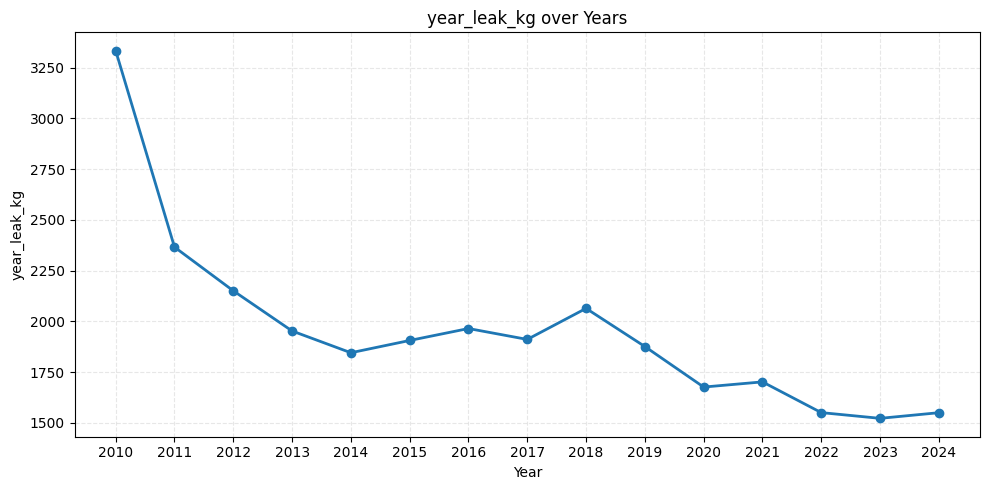

In [3]:
# yearly leak plot
import pandas as pd
import matplotlib.pyplot as plt

# 读取 CSV（把 'your_data.csv' 换成你的文件名/路径）
df = pd.read_csv("/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE2027July/4Method/Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_year_summary.csv")

# 确保按年份排序（可选，但推荐）
df = df.sort_values("year")

# 绘图
plt.figure(figsize=(10, 5))
plt.plot(df["year"], df["year_leak_kg"], marker="o", linewidth=2, markersize=6)

plt.xlabel("Year")
plt.ylabel("year_leak_kg")
plt.title("year_leak_kg over Years")

# 如果年份是整数且不多，可以显示每一年
if (df["year"].max() - df["year"].min()) <= 20:
    plt.xticks(df["year"])

plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

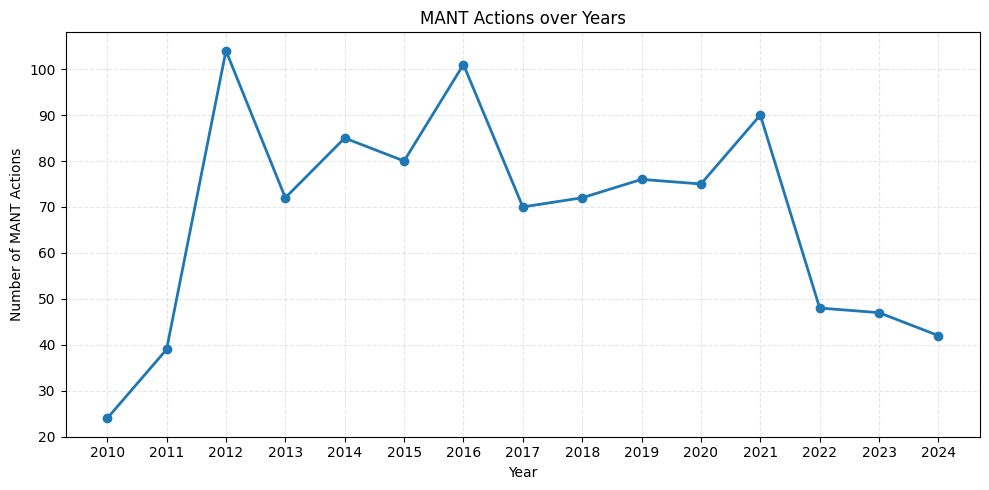

In [4]:
# yearly nb of mant plot
import pandas as pd
import matplotlib.pyplot as plt

# 读取 CSV（把 'your_data.csv' 换成你的文件名/路径）
df = pd.read_csv("/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/RTE2027July/4Method/Result_opt_variantAlpha_muMANT/gurobi_rolling_mant_year_summary.csv")

# 确保按年份排序（可选，但推荐）
df = df.sort_values("year")

# 绘图
plt.figure(figsize=(10, 5))
plt.plot(df["year"], df["selected_count"], marker="o", linewidth=2, markersize=6)

plt.xlabel("Year")
plt.ylabel("Number of MANT Actions")
plt.title("MANT Actions over Years")

# 如果年份是整数且不多，可以显示每一年
if (df["year"].max() - df["year"].min()) <= 20:
    plt.xticks(df["year"])

plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()